# MSCS 634 – Project Deliverable 3
## Classification, Clustering, and Pattern Mining
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling
**Student:** Ruchitha Musku
**Dataset:** IBM Telco Customer Churn, cleaned in Deliverable 1 (7,043 customers)

---
### Contents
**Part A – Classification (predicting churn)**
1. Data preparation
2. Baseline classification models: Decision Tree, k-NN, Naïve Bayes, SVM (plus Logistic Regression as a reference)
3. Hyperparameter tuning of the Decision Tree with `GridSearchCV`
4. Evaluation: confusion matrices, ROC curves, accuracy, precision, recall, F1, ROC-AUC

**Part B – Clustering (customer segmentation)**
5. K-Means: choosing *k*, fitting, visualising and profiling the segments
6. Hierarchical clustering for comparison

**Part C – Association rule mining**
7. Building transactions, Apriori vs FP-Growth
8. Churn rules, retention rules and cross-sell rules
9. Real-world applications

**Part D – Summary of insights**

In [1]:
# --- Imports -----------------------------------------------------------------
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Classification
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
# Clustering
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
# Association rules
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import networkx as nx

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
os.makedirs("figures", exist_ok=True)
RANDOM_STATE = 42

In [2]:
# --- Load the cleaned dataset from Deliverable 1 ------------------------------
df = pd.read_csv("data/telco_churn_cleaned.csv")
print("Shape:", df.shape, "| missing values:", int(df.isnull().sum().sum()))

# Engineered features reused from Deliverable 2
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_addons"] = (df[addon_cols] == "Yes").sum(axis=1)
df["auto_payment"] = df["PaymentMethod"].str.contains("auto").astype(int)
df["has_family"] = ((df["Partner"] == "Yes") | (df["Dependents"] == "Yes")).astype(int)
df["contract_months"] = df["Contract"].map({"Month-to-month": 1, "One year": 12, "Two year": 24})
df.head(3)

Shape: (7043, 21) | missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag,num_addons,auto_payment,has_family,contract_months
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,1,0,1,1
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,2,0,0,12
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,2,0,0,1


---
# Part A – Classification: Predicting Customer Churn

**Goal:** predict whether a customer will churn (`Churn` = Yes/No) from their demographics, account and service information.
A good model lets the company target retention offers *before* customers leave.

**Things to keep in mind from Deliverable 1:**
- **Class imbalance:** only 26.5% of customers churn. A model that always predicts "No" would be 73.5% accurate and useless,
  so **F1-score (for the churn class) and ROC-AUC** are the main metrics, and splits are **stratified**.
- **Different feature scales** (tenure 0–72, TotalCharges 0–8,685): k-NN and SVM rely on distances, so features are **standardised**
  inside pipelines (the scaler is fit only on training data).

## 1. Data Preparation

In [3]:
# One-hot encode the categorical predictors (drop_first avoids redundant dummy columns)
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
            "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod"]
X = pd.get_dummies(df.drop(columns=["Churn", "Churn_flag"]), columns=cat_cols, drop_first=True, dtype=float)
y = df["Churn_flag"].values      # 1 = churned, 0 = stayed

# Stratified 80/20 split keeps the 26.5% churn rate in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Features: {X.shape[1]}")
print(f"Train: {X_train.shape[0]:,} rows (churn rate {y_train.mean():.1%})")
print(f"Test : {X_test.shape[0]:,} rows (churn rate {y_test.mean():.1%})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Features: 27
Train: 5,634 rows (churn rate 26.5%)
Test : 1,409 rows (churn rate 26.5%)


## 2. Baseline Classification Models

| Model | How it works | Settings and why |
|---|---|---|
| **Decision Tree (default)** | Splits the data with if/then rules | Default settings (fully grown tree) to show the starting point *before* tuning |
| **k-Nearest Neighbours** | Predicts by majority vote of the *k* most similar customers | Standardised features; *k* chosen with a validation curve (below) |
| **Gaussian Naïve Bayes** | Probabilistic model assuming features are independent given the class | No hyperparameters to tune; fast baseline |
| **Support Vector Machine** | Finds the maximum-margin boundary, with an RBF kernel for non-linear patterns | Standardised features, `class_weight="balanced"` to counter the imbalance |
| **Logistic Regression** (reference) | Linear probabilistic classifier | Standard benchmark for churn problems, `class_weight="balanced"` |

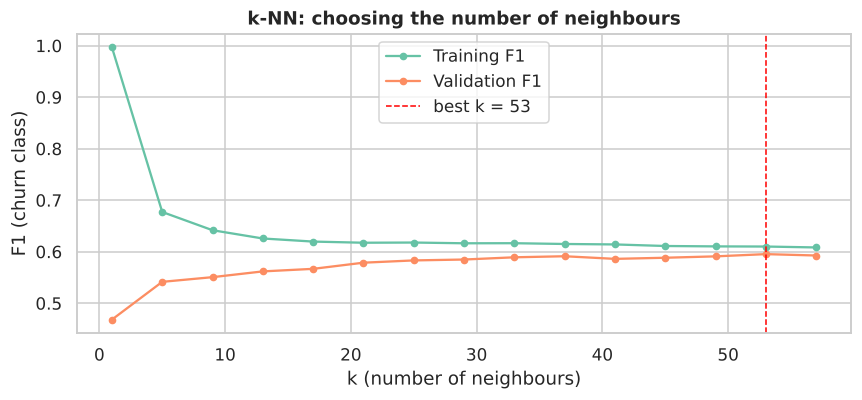

Selected k = 53. A small k overfits (training F1 near 1.0); a larger k smooths the decision boundary.


In [4]:
# --- Choose k for k-NN with a validation curve (5-fold stratified CV on the training data) ---
k_range = list(range(1, 61, 4))
knn_pipe = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())])
tr_f1, va_f1 = validation_curve(knn_pipe, X_train, y_train, param_name="model__n_neighbors",
                                param_range=k_range, cv=cv, scoring="f1", n_jobs=-1)
best_k = k_range[int(np.argmax(va_f1.mean(1)))]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(k_range, tr_f1.mean(1), "o-", ms=4, label="Training F1")
ax.plot(k_range, va_f1.mean(1), "o-", ms=4, label="Validation F1")
ax.axvline(best_k, color="red", ls="--", lw=1, label=f"best k = {best_k}")
ax.set(title="k-NN: choosing the number of neighbours", xlabel="k (number of neighbours)", ylabel="F1 (churn class)")
ax.legend()
plt.tight_layout(); plt.savefig("figures/knn_k_selection.png", bbox_inches="tight"); plt.show()
print(f"Selected k = {best_k}. A small k overfits (training F1 near 1.0); a larger k smooths the decision boundary.")

In [5]:
models = {
    "Decision Tree (default)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "k-NN": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=best_k))]),
    "Naive Bayes": Pipeline([("scaler", StandardScaler()), ("model", GaussianNB())]),
    "SVM (RBF)": Pipeline([("scaler", StandardScaler()),
                           ("model", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE))]),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=5000, class_weight="balanced"))]),
}

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows[name] = {f"CV {m}": res[f"test_{m}"].mean() for m in scoring}
    print(f"{name:<25} CV F1 = {res['test_f1'].mean():.3f}   CV ROC-AUC = {res['test_roc_auc'].mean():.3f}")
pd.DataFrame(cv_rows).T.round(3)

Decision Tree (default)   CV F1 = 0.482   CV ROC-AUC = 0.649


k-NN                      CV F1 = 0.595   CV ROC-AUC = 0.831
Naive Bayes               CV F1 = 0.617   CV ROC-AUC = 0.831


SVM (RBF)                 CV F1 = 0.621   CV ROC-AUC = 0.827
Logistic Regression       CV F1 = 0.629   CV ROC-AUC = 0.846


,CV accuracy,CV precision,CV recall,CV f1,CV roc_auc
Decision Tree (default),0.725,0.481,0.484,0.482,0.649
k-NN,0.794,0.622,0.572,0.595,0.831
Naive Bayes,0.739,0.505,0.794,0.617,0.831
SVM (RBF),0.749,0.518,0.775,0.621,0.827
Logistic Regression,0.750,0.518,0.801,0.629,0.846


The **untuned Decision Tree performs worst** (lowest F1 and ROC-AUC). A fully grown tree memorises the training data and
overfits. This makes it the natural choice for hyperparameter tuning.

## 3. Hyperparameter Tuning: Decision Tree with GridSearchCV

**Technique:** an exhaustive **grid search with 5-fold stratified cross-validation** (`GridSearchCV`). Every combination of
the hyperparameters below is trained and validated on 5 different folds of the training data. The combination with the
highest **mean F1-score** (churn class) is selected and refit on the whole training set. The test set is not touched during tuning.

| Hyperparameter | Values searched | What it controls |
|---|---|---|
| `criterion` | gini, entropy | How split quality is measured |
| `max_depth` | 3, 4, 5, 6, 7, 8, 10, 12, None | Maximum tree depth: the main control on complexity and overfitting |
| `min_samples_leaf` | 1, 5, 10, 20, 40, 80 | Minimum customers per leaf: stops rules based on very few customers |
| `class_weight` | None, balanced | `balanced` gives churners more weight to counter the 73/27 imbalance |
| `ccp_alpha` | 0, 0.0005, 0.001, 0.003 | Cost-complexity pruning: removes branches that add little |

F1 was chosen as the selection metric because it balances **precision** (not wasting retention offers on loyal customers)
and **recall** (not missing customers who are about to leave).

In [6]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 7, 8, 10, 12, None],
    "min_samples_leaf": [1, 5, 10, 20, 40, 80],
    "class_weight": [None, "balanced"],
    "ccp_alpha": [0.0, 0.0005, 0.001, 0.003],
}
n_combos = int(np.prod([len(v) for v in param_grid.values()]))
print(f"Grid size: {n_combos} combinations x 5 folds = {n_combos * 5:,} model fits")

grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                    scoring={"f1": "f1", "roc_auc": "roc_auc", "accuracy": "accuracy"},
                    refit="f1", cv=cv, n_jobs=-1, return_train_score=True)
t0 = time.time()
grid.fit(X_train, y_train)
print(f"Search finished in {time.time() - t0:.1f} s")
print("\nBest hyperparameters:", grid.best_params_)
print(f"Best mean CV F1: {grid.best_score_:.3f}")
bi = grid.best_index_
print(f"Mean CV ROC-AUC of the best model: {grid.cv_results_['mean_test_roc_auc'][bi]:.3f}")
print(f"Mean train F1 vs CV F1: {grid.cv_results_['mean_train_f1'][bi]:.3f} vs {grid.best_score_:.3f} "
      "(small gap = little overfitting)")

Grid size: 864 combinations x 5 folds = 4,320 model fits


Search finished in 79.0 s

Best hyperparameters: {'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}
Best mean CV F1: 0.619
Mean CV ROC-AUC of the best model: 0.816
Mean train F1 vs CV F1: 0.622 vs 0.619 (small gap = little overfitting)


In [7]:
# --- Top 10 parameter combinations -------------------------------------------
res = pd.DataFrame(grid.cv_results_)
top10 = (res.sort_values("rank_test_f1")
         [["param_criterion", "param_max_depth", "param_min_samples_leaf", "param_class_weight", "param_ccp_alpha",
           "mean_test_f1", "std_test_f1", "mean_test_roc_auc", "mean_train_f1"]].head(10))
top10.columns = ["criterion", "max_depth", "min_samples_leaf", "class_weight", "ccp_alpha",
                 "CV F1", "CV F1 std", "CV ROC-AUC", "Train F1"]
top10.round(4)

,criterion,max_depth,min_samples_leaf,class_weight,ccp_alpha,CV F1,CV F1 std,CV ROC-AUC,Train F1
541,gini,3,5,balanced,0.001,0.6194,0.0182,0.8161,0.6223
542,gini,3,10,balanced,0.001,0.6194,0.0182,0.8161,0.6223
545,gini,3,80,balanced,0.001,0.6194,0.0182,0.8161,0.6223
544,gini,3,40,balanced,0.001,0.6194,0.0182,0.8161,0.6223
543,gini,3,20,balanced,0.001,0.6194,0.0182,0.8161,0.6223
540,gini,3,1,balanced,0.001,0.6194,0.0182,0.8161,0.6223
596,entropy,3,10,balanced,0.001,0.6194,0.0182,0.8169,0.6223
597,entropy,3,20,balanced,0.001,0.6194,0.0182,0.8169,0.6223
595,entropy,3,5,balanced,0.001,0.6194,0.0182,0.8169,0.6223
594,entropy,3,1,balanced,0.001,0.6194,0.0182,0.8169,0.6223


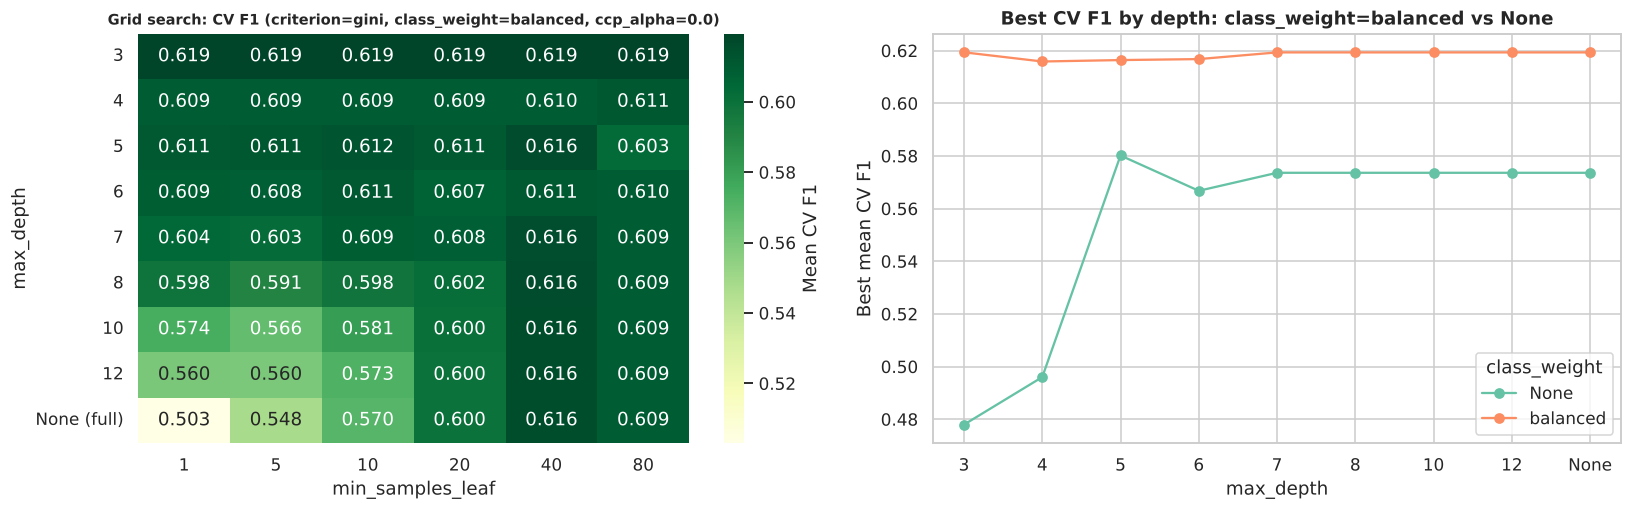

In [8]:
# --- Visualise the search: CV F1 over max_depth x min_samples_leaf ----------------
# (other hyperparameters fixed at their best values)
bp = grid.best_params_
to_str = lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(int(v)) if isinstance(v, (int, float, np.integer, np.floating)) else str(v)
res["depth_s"] = res["param_max_depth"].apply(to_str)
res["cw_s"] = res["param_class_weight"].apply(lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
sub = res[(res.param_criterion == bp["criterion"]) & (res.cw_s == str(bp["class_weight"])) &
          (res.param_ccp_alpha == bp["ccp_alpha"])].copy()
sub["max_depth"] = sub["depth_s"].replace("None", "None (full)")
heat = sub.pivot_table(index="max_depth", columns="param_min_samples_leaf", values="mean_test_f1")
heat = heat.reindex([str(d) for d in [3, 4, 5, 6, 7, 8, 10, 12]] + ["None (full)"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGn", ax=axes[0], cbar_kws={"label": "Mean CV F1"})
axes[0].set(title=f"Grid search: CV F1 (criterion={bp['criterion']}, class_weight={bp['class_weight']}, "
                  f"ccp_alpha={bp['ccp_alpha']})", xlabel="min_samples_leaf", ylabel="max_depth")
axes[0].title.set_fontsize(9.5)

# Effect of class_weight and depth (best of the other params per cell)
eff = res.groupby(["depth_s", "cw_s"])["mean_test_f1"].max().unstack()
eff = eff.reindex([str(d) for d in [3, 4, 5, 6, 7, 8, 10, 12]] + ["None"])
eff.plot(marker="o", ax=axes[1])
axes[1].set(title="Best CV F1 by depth: class_weight=balanced vs None", xlabel="max_depth", ylabel="Best mean CV F1")
axes[1].legend(title="class_weight")
plt.tight_layout(); plt.savefig("figures/dt_grid_search.png", bbox_inches="tight"); plt.show()

**Interpreting the chosen parameters** (`max_depth=3`, `class_weight="balanced"`, `criterion="gini"`):
- **A shallow tree (depth 3, only 8 leaves) gives the best F1.** The default tree grew to depth 25 with more than 1,000 leaves and overfit badly.
- **Deep trees only recover when leaves are forced to be large.** In the heatmap, deep trees with `min_samples_leaf` = 1–10 score worst
  (as low as 0.50 for an unlimited tree), but with `min_samples_leaf = 40` they reach ≈0.616. Both depth limits and leaf-size limits do the same job: they stop
  the tree from learning rules from a handful of customers.
- **`min_samples_leaf` and `ccp_alpha` make no difference at depth 3.** A depth-3 tree's leaves already hold hundreds of customers and it
  has no weak branches to prune, so many combinations tie on CV F1. Among tied combinations, `GridSearchCV` keeps the first one in the grid.
- **`class_weight="balanced"` is the single most important setting.** It lifts F1 at every depth (right-hand plot) because, without it, the
  tree favours the majority "stay" class and misses many churners.
- Training F1 (0.622) and CV F1 (0.619) are almost identical, so **the tuned model does not overfit**, and a three-level tree is
  simple enough to explain to a business audience.

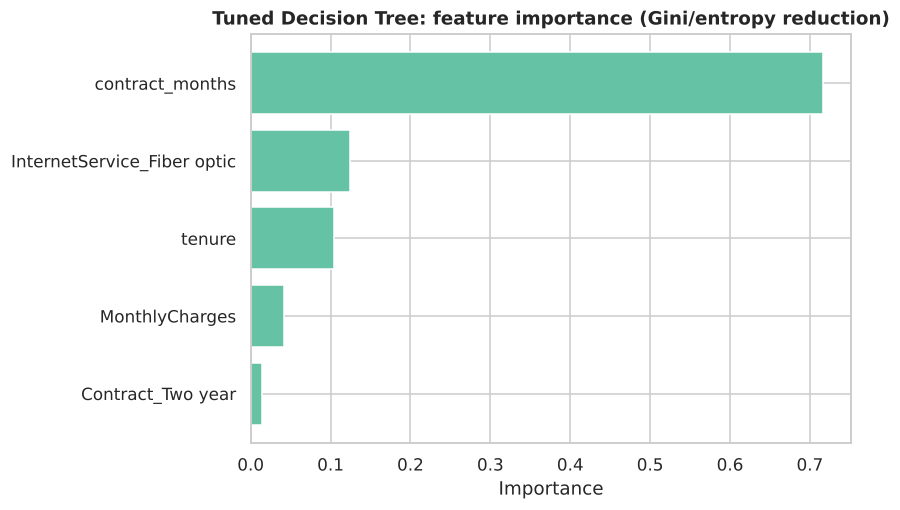

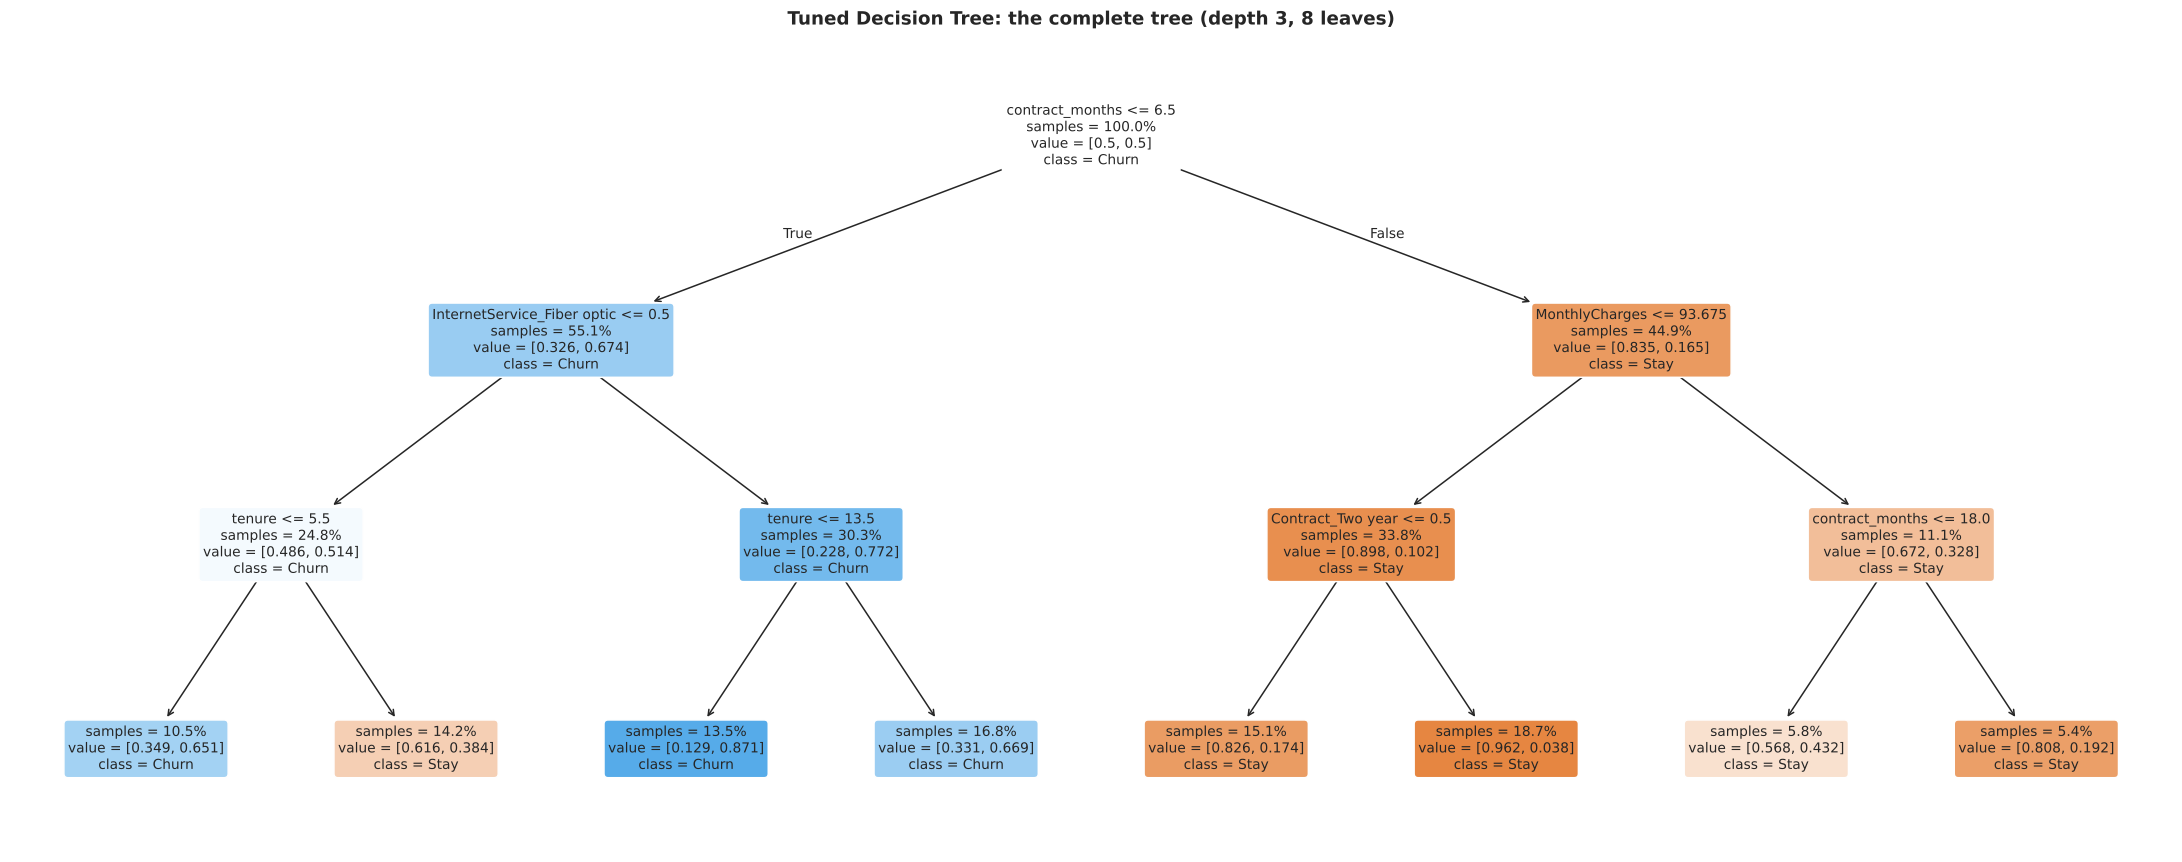

In [9]:
# --- Tuned tree: feature importances and top of the tree --------------------------
best_tree = grid.best_estimator_
imp = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False)
imp = imp[imp > 0].head(12)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(imp.index[::-1], imp.values[::-1], color="#66c2a5")
ax.set(title="Tuned Decision Tree: feature importance (Gini/entropy reduction)", xlabel="Importance")
plt.tight_layout(); plt.savefig("figures/dt_feature_importance.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(best_tree, feature_names=X.columns, class_names=["Stay", "Churn"], filled=True,
          rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax)
ax.set_title("Tuned Decision Tree: the complete tree (depth 3, 8 leaves)")
plt.tight_layout(); plt.savefig("figures/dt_tree_top_levels.png", bbox_inches="tight"); plt.show()

## 4. Evaluation on the Held-out Test Set

In [10]:
# Add the tuned tree to the model set, fit everything on the full training data and evaluate on the test set
models["Decision Tree (tuned)"] = best_tree
order = ["Decision Tree (default)", "Decision Tree (tuned)", "k-NN", "Naive Bayes", "SVM (RBF)", "Logistic Regression"]

test_rows, probas, preds = {}, {}, {}
for name in order:
    m = models[name]
    if name != "Decision Tree (tuned)":          # the tuned tree is already refit on the full training set
        m.fit(X_train, y_train)
    p = m.predict(X_test)
    pr = m.predict_proba(X_test)[:, 1]
    preds[name], probas[name] = p, pr
    test_rows[name] = {"Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                       "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, pr)}

cv_rows["Decision Tree (tuned)"] = {"CV f1": grid.best_score_,
                                    "CV roc_auc": grid.cv_results_["mean_test_roc_auc"][bi]}
results = pd.DataFrame(test_rows).T.loc[order]
results.insert(0, "CV F1", [cv_rows[n]["CV f1"] for n in order])
results.to_csv("classification_results.csv")
results.style.format("{:.3f}").highlight_max(subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"], color="#c7e9c0")

,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree (default),0.482,0.730,0.492,0.505,0.499,0.658
Decision Tree (tuned),0.619,0.746,0.514,0.783,0.621,0.816
k-NN,0.595,0.776,0.580,0.570,0.575,0.819
Naive Bayes,0.617,0.732,0.497,0.778,0.606,0.821
SVM (RBF),0.621,0.742,0.509,0.757,0.609,0.818
Logistic Regression,0.629,0.739,0.505,0.781,0.613,0.841


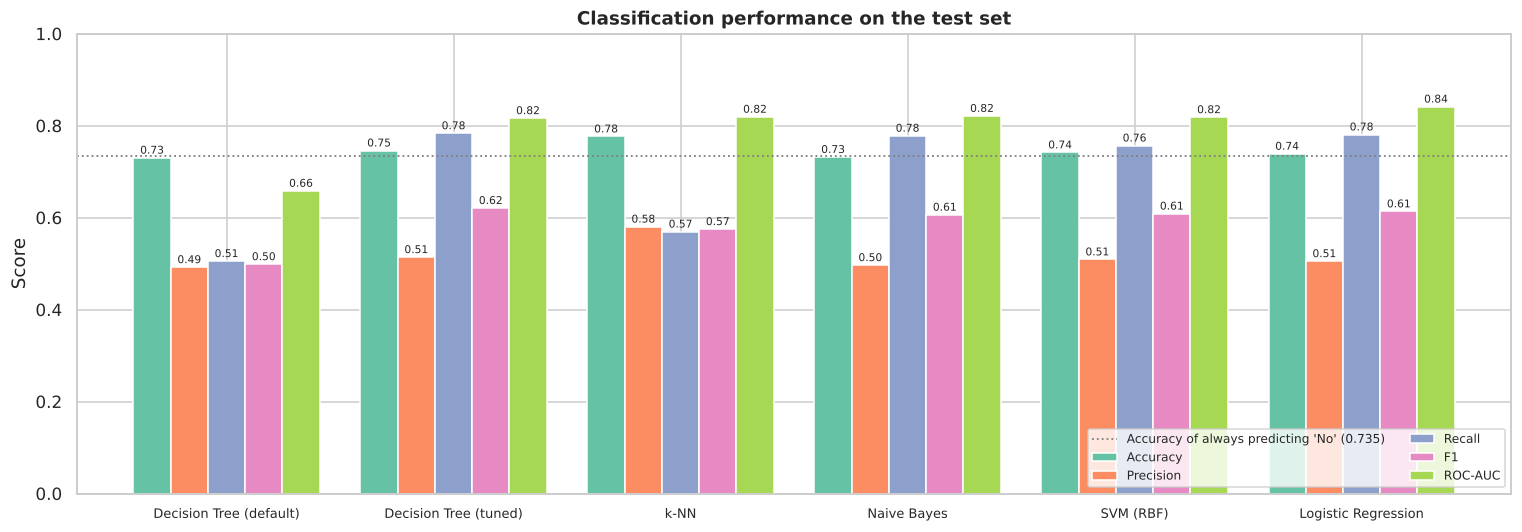

In [11]:
# --- 4.1 Metric comparison bar chart -----------------------------------------------
fig, ax = plt.subplots(figsize=(14, 5))
results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot.bar(ax=ax, width=0.82,
                                                                       color=sns.color_palette("Set2", 5))
ax.axhline(1 - y_test.mean(), color="grey", ls=":", lw=1.2, label=f"Accuracy of always predicting 'No' ({1 - y_test.mean():.3f})")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7, padding=1)
ax.set(title="Classification performance on the test set", ylabel="Score", ylim=(0, 1.0), xlabel="")
ax.tick_params(axis="x", rotation=0, labelsize=8.5)
ax.legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig("figures/classification_metrics_comparison.png", bbox_inches="tight"); plt.show()

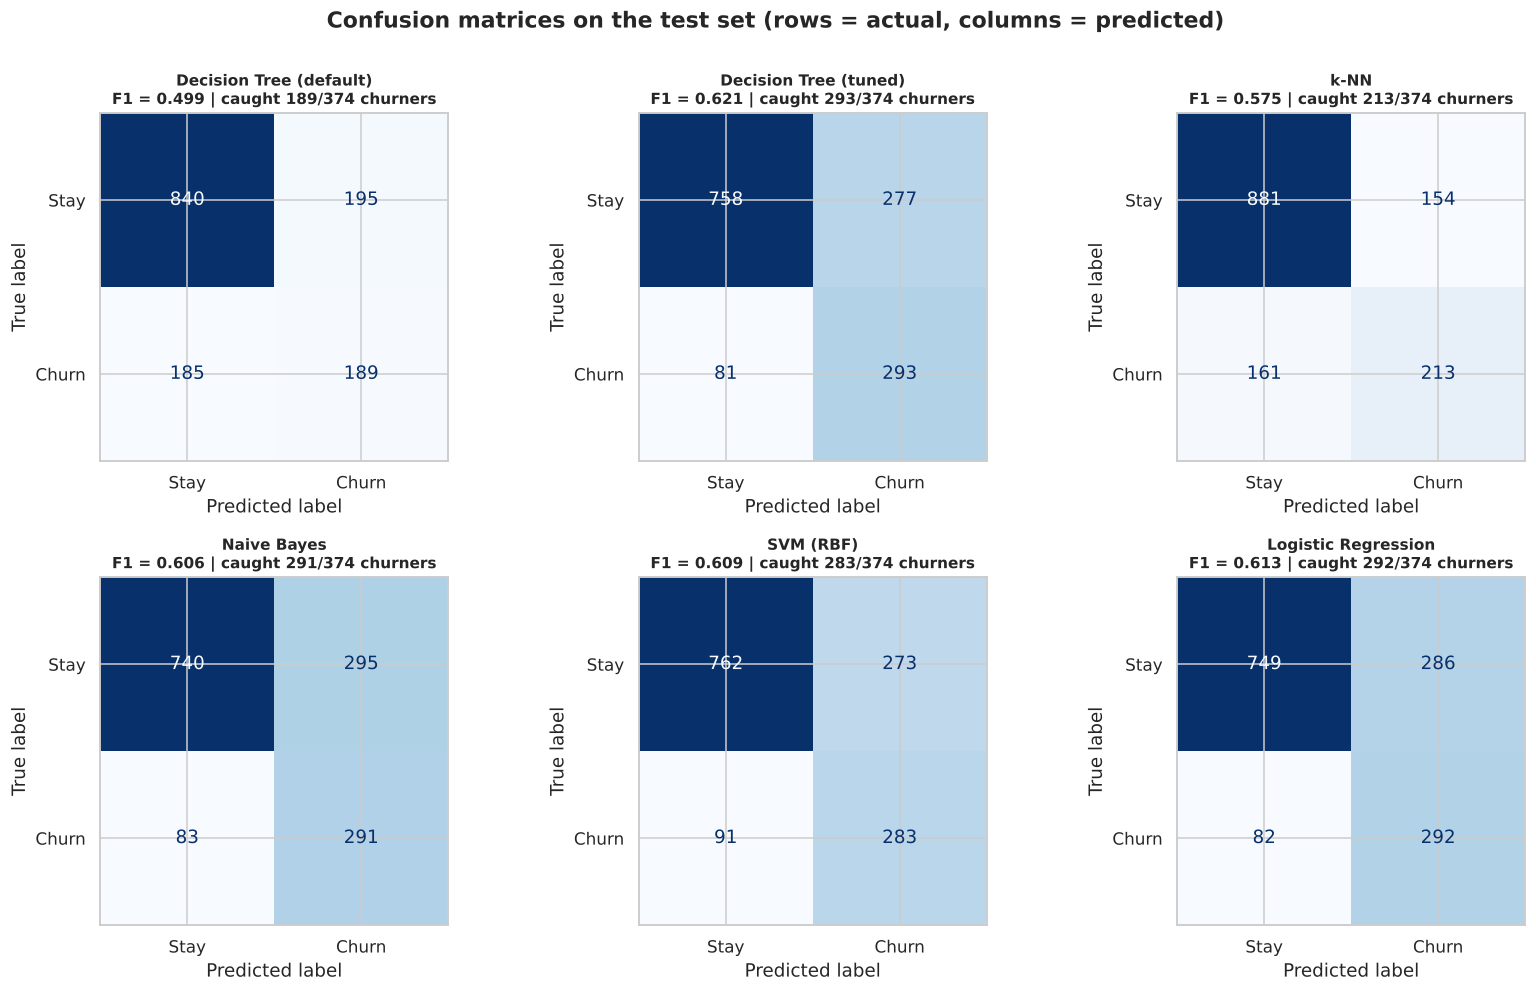

In [12]:
# --- 4.2 Confusion matrices -----------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.flat, order):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nF1 = {results.loc[name, 'F1']:.3f} | caught {tp}/{tp + fn} churners", fontsize=10)
fig.suptitle("Confusion matrices on the test set (rows = actual, columns = predicted)", weight="bold", y=1.0)
plt.tight_layout(); plt.savefig("figures/confusion_matrices.png", bbox_inches="tight"); plt.show()

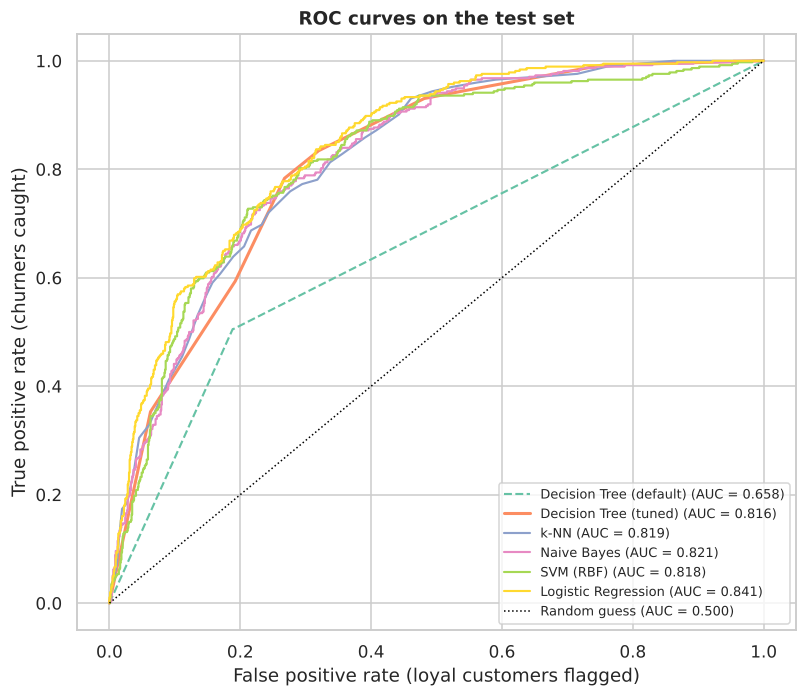

In [13]:
# --- 4.3 ROC curves -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for name in order:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    ax.plot(fpr, tpr, lw=2 if "tuned" in name else 1.4, ls="--" if "default" in name else "-",
            label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1, label="Random guess (AUC = 0.500)")
ax.set(title="ROC curves on the test set", xlabel="False positive rate (loyal customers flagged)",
       ylabel="True positive rate (churners caught)")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.savefig("figures/roc_curves.png", bbox_inches="tight"); plt.show()

In [14]:
# --- 4.4 Before vs after tuning ------------------------------------------------------
cmp = results.loc[["Decision Tree (default)", "Decision Tree (tuned)"], ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
cmp.loc["Improvement"] = cmp.iloc[1] - cmp.iloc[0]
print("Decision tree before vs after hyperparameter tuning (test set):")
display(cmp.round(3))
print(f"Tuned tree depth = {best_tree.get_depth()}, leaves = {best_tree.get_n_leaves()} "
      f"(default tree: depth = {models['Decision Tree (default)'].get_depth()}, "
      f"leaves = {models['Decision Tree (default)'].get_n_leaves()})")

Decision tree before vs after hyperparameter tuning (test set):


,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree (default),0.730,0.492,0.505,0.499,0.658
Decision Tree (tuned),0.746,0.514,0.783,0.621,0.816
Improvement,0.016,0.022,0.278,0.122,0.158


Tuned tree depth = 3, leaves = 8 (default tree: depth = 25, leaves = 1101)


In [15]:
# Detailed per-class report for the tuned decision tree
print(classification_report(y_test, preds["Decision Tree (tuned)"], target_names=["Stay", "Churn"], digits=3))

              precision    recall  f1-score   support

        Stay      0.903     0.732     0.809      1035
       Churn      0.514     0.783     0.621       374

    accuracy                          0.746      1409
   macro avg      0.709     0.758     0.715      1409
weighted avg      0.800     0.746     0.759      1409



**Classification takeaways**
- **Accuracy is misleading here.** k-NN has the *highest* accuracy (0.776) but catches only 57% of churners and has the lowest F1 of the
  tuned or well-configured models. F1, recall and ROC-AUC tell the real story.
- **Tuning transformed the Decision Tree**: from the worst model to one competitive with SVM and Logistic Regression, while staying
  small and readable. The tuned tree's top splits (contract type, tenure, internet service) are rules a retention team can use directly.
- **The tuned Decision Tree has the best F1 (0.621)** and Logistic Regression the best ROC-AUC (0.841). The models with balanced class
  weights (tuned tree, SVM, Logistic Regression) and Naïve Bayes catch about 76–78% of churners, at the cost of more false alarms. For retention that trade-off is usually worth it: a discount offered to a loyal customer costs far less than losing a customer.

---
# Part B – Clustering: Customer Segmentation

**Goal:** group customers into segments with similar *relationship and spending profiles* without using the churn label,
then check how churn differs between the segments that were discovered.

**Features used** (standardised, so each contributes equally to the distance):
- `tenure`: length of relationship
- `MonthlyCharges`: price level
- `num_addons`: depth of the service bundle (0–6)
- `contract_months`: commitment level (1, 12, 24)

`TotalCharges` was left out because it is largely tenure × MonthlyCharges (Deliverable 2) and would double-count those two dimensions.

## 5. K-Means Clustering

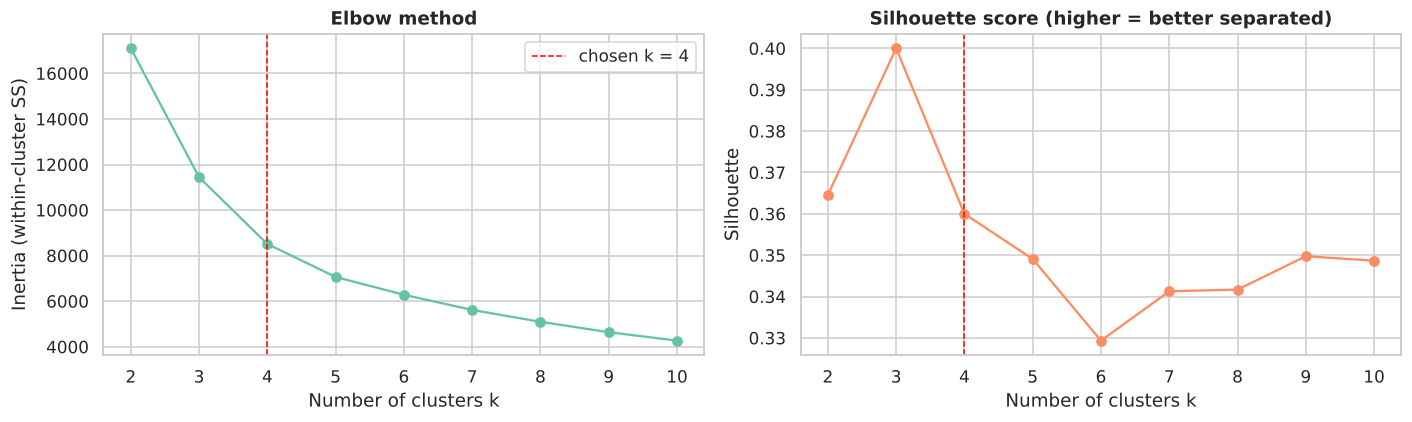

k,2,3,4,5,6,7,8,9,10
inertia,17101.000,11443.0,8510.00,7063.000,6283.000,5615.000,5094.000,4639.00,4269.000
silhouette,0.365,0.4,0.36,0.349,0.329,0.341,0.342,0.35,0.349
inertia drop vs k-1,NaN,5658.0,2933.00,1448.000,779.000,668.000,521.000,455.00,370.000


In [16]:
clu_features = ["tenure", "MonthlyCharges", "num_addons", "contract_months"]
scaler_c = StandardScaler()
Z = scaler_c.fit_transform(df[clu_features])

# --- Choose k: elbow method (inertia) and silhouette score ------------------------
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(list(ks), inertia, "o-"); ax[0].axvline(4, color="red", ls="--", lw=1, label="chosen k = 4")
ax[0].set(title="Elbow method", xlabel="Number of clusters k", ylabel="Inertia (within-cluster SS)"); ax[0].legend()
ax[1].plot(list(ks), sil, "o-", color="#fc8d62"); ax[1].axvline(4, color="red", ls="--", lw=1)
ax[1].set(title="Silhouette score (higher = better separated)", xlabel="Number of clusters k", ylabel="Silhouette")
plt.tight_layout(); plt.savefig("figures/kmeans_k_selection.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 0), "silhouette": np.round(sil, 3),
              "inertia drop vs k-1": np.r_[np.nan, -np.diff(inertia)].round(0)}).set_index("k").T

**Choosing k = 4.** The silhouette score peaks at k = 3, with k = 4 close behind, and the elbow curve flattens after k = 4 (the reduction in
inertia roughly halves from k = 4 to k = 5). We choose **k = 4** because it keeps good separation while splitting the very large
high-churn group found at k = 3 into **two segments that need different retention strategies** (new low-spend customers vs
established high-spend customers without contracts). In segmentation, being able to act on the clusters is as important as the
statistical score.

In [17]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Z)
df["cluster_id"] = kmeans.labels_
print(f"Silhouette score for k = {K}: {silhouette_score(Z, kmeans.labels_):.3f}")

# --- Profile each cluster (churn is NOT used for clustering, only for interpretation) ---
profile = df.groupby("cluster_id").agg(
    customers=("tenure", "size"), tenure=("tenure", "mean"), monthly_charges=("MonthlyCharges", "mean"),
    num_addons=("num_addons", "mean"), contract_months=("contract_months", "mean"),
    pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean() * 100),
    pct_no_internet=("InternetService", lambda s: (s == "No").mean() * 100),
    pct_month_to_month=("Contract", lambda s: (s == "Month-to-month").mean() * 100),
    pct_electronic_check=("PaymentMethod", lambda s: (s == "Electronic check").mean() * 100),
    churn_rate=("Churn_flag", lambda s: s.mean() * 100))

# --- Give each cluster a descriptive name based on its profile ----------------------
names = {}
remaining = set(profile.index)
c = profile.loc[list(remaining), "pct_no_internet"].idxmax(); names[c] = "Basic Phone-Only Loyalists"; remaining.remove(c)
c = profile.loc[list(remaining), "tenure"].idxmin();          names[c] = "New Low-Commitment Customers"; remaining.remove(c)
c = profile.loc[list(remaining), "contract_months"].idxmax(); names[c] = "Established Premium Bundlers"; remaining.remove(c)
c = remaining.pop();                                          names[c] = "High-Spend Flexible (At Risk)"
df["segment"] = df["cluster_id"].map(names)
profile.index = profile.index.map(names)
profile = profile.sort_values("churn_rate", ascending=False)
profile["share_%"] = profile["customers"] / len(df) * 100
profile.to_csv("cluster_profiles.csv")
profile.round(1)

Silhouette score for k = 4: 0.360


,customers,tenure,monthly_charges,num_addons,contract_months,pct_fiber,pct_no_internet,pct_month_to_month,pct_electronic_check,churn_rate,share_%
cluster_id,,,,,,,,,,,
High-Spend Flexible (At Risk),2151,28.4,84.6,2.7,2.7,73.8,0.0,84.2,51.2,39.3,30.5
New Low-Commitment Customers,2228,9.2,46.9,0.6,1.9,29.6,28.6,92.1,38.6,38.9,31.6
Established Premium Bundlers,1629,60.6,88.3,4.3,19.2,51.7,0.0,0.6,21.2,8.7,23.1
Basic Phone-Only Loyalists,1035,46.1,24.9,0.3,20.2,0.6,85.8,0.2,5.6,1.5,14.7


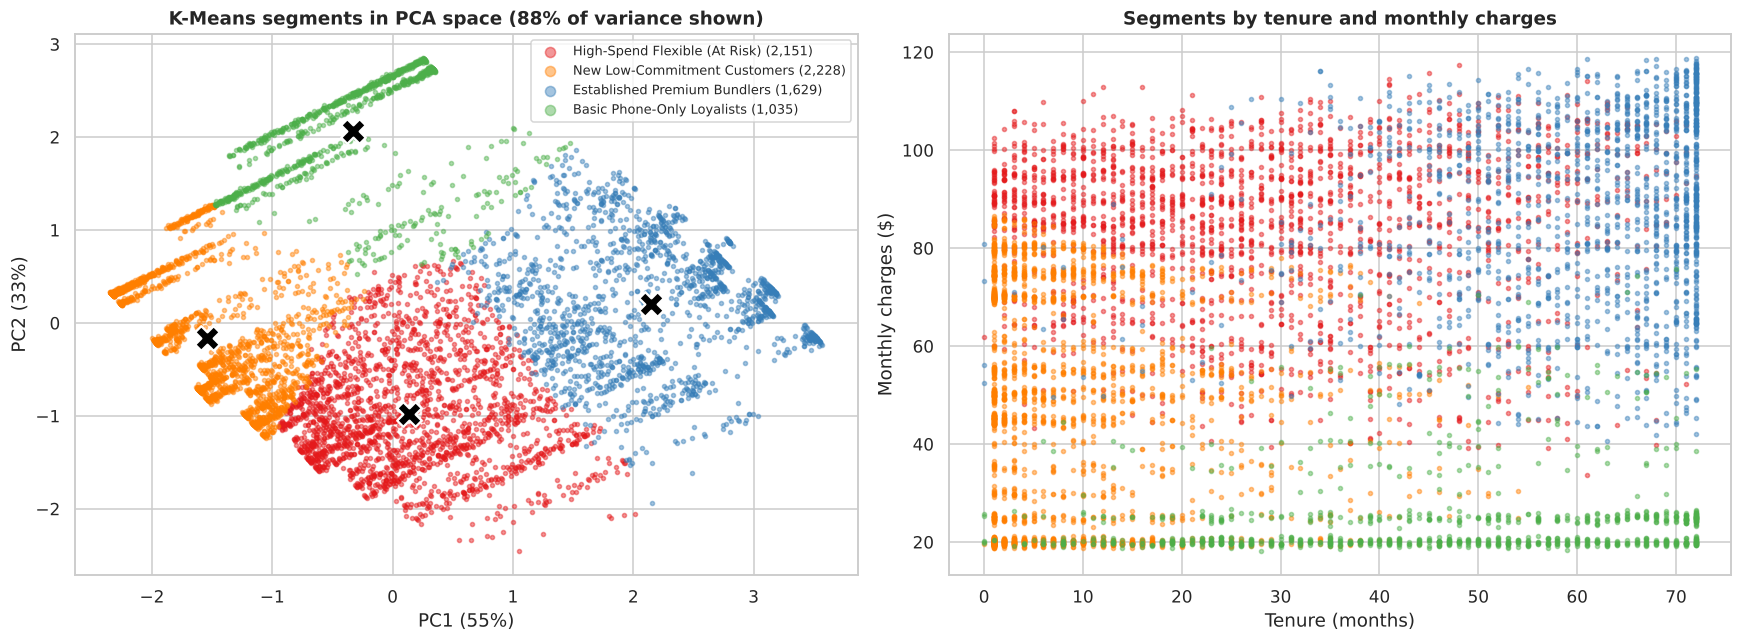

In [18]:
# --- 5.1 Visualise clusters in 2-D with PCA -----------------------------------------
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Z)
centers = pca.transform(kmeans.cluster_centers_)
seg_order = profile.index.tolist()
palette = dict(zip(seg_order, ["#e41a1c", "#ff7f00", "#377eb8", "#4daf4a"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for seg in seg_order:
    m = df["segment"] == seg
    axes[0].scatter(P[m, 0], P[m, 1], s=7, alpha=.45, color=palette[seg], label=f"{seg} ({m.sum():,})")
for cid, (cx, cy) in enumerate(centers):
    axes[0].scatter(cx, cy, s=260, marker="X", color="black", edgecolor="white", lw=1.5)
axes[0].set(title=f"K-Means segments in PCA space ({pca.explained_variance_ratio_.sum():.0%} of variance shown)",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[0].legend(fontsize=8.5, markerscale=2.5, loc="best")

# Same clusters in the original, interpretable feature space
for seg in seg_order:
    m = df["segment"] == seg
    axes[1].scatter(df.loc[m, "tenure"], df.loc[m, "MonthlyCharges"], s=7, alpha=.45, color=palette[seg], label=seg)
axes[1].set(title="Segments by tenure and monthly charges", xlabel="Tenure (months)", ylabel="Monthly charges ($)")
plt.tight_layout(); plt.savefig("figures/kmeans_clusters_scatter.png", bbox_inches="tight"); plt.show()

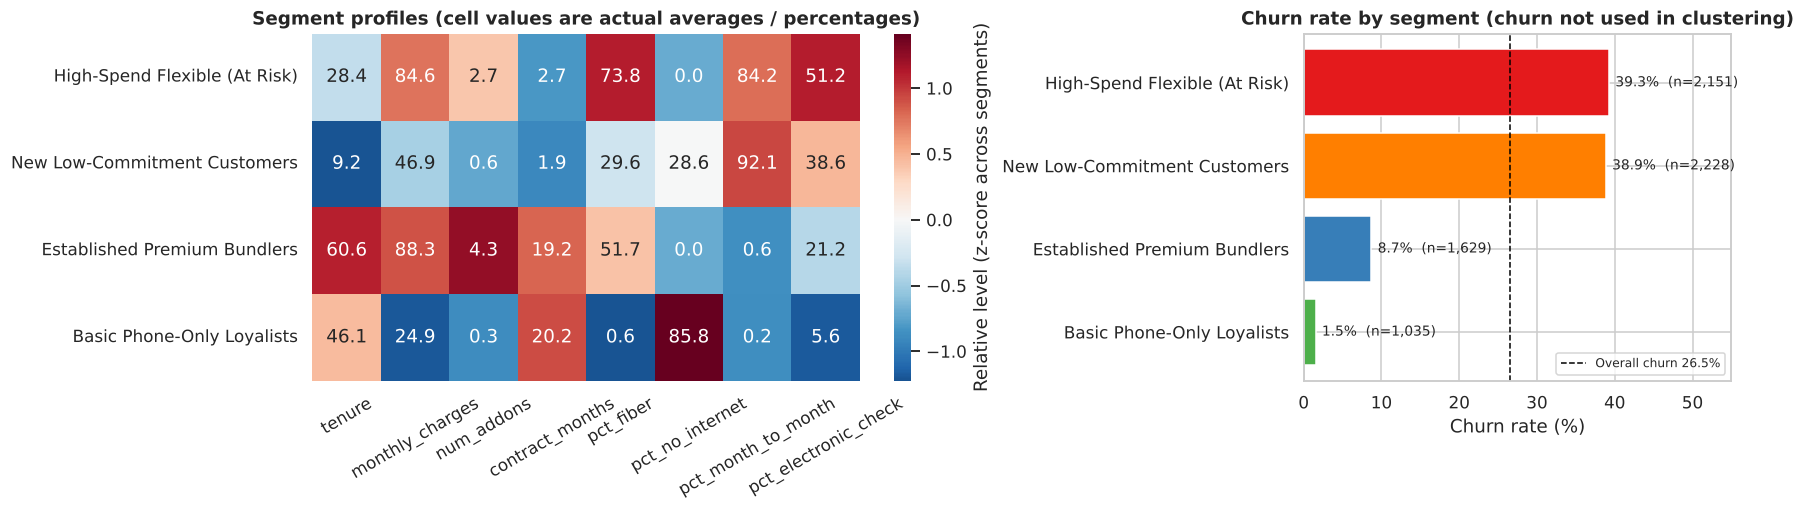

In [19]:
# --- 5.2 Cluster profile heatmap and churn rate per segment ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
prof_cols = ["tenure", "monthly_charges", "num_addons", "contract_months", "pct_fiber", "pct_no_internet",
             "pct_month_to_month", "pct_electronic_check"]
# Colour by standardised value (relative to the other segments), annotate with actual values
rel = (profile[prof_cols] - profile[prof_cols].mean()) / profile[prof_cols].std()
sns.heatmap(rel, annot=profile[prof_cols].round(1), fmt="", cmap="RdBu_r", center=0, ax=axes[0],
            cbar_kws={"label": "Relative level (z-score across segments)"})
axes[0].set(title="Segment profiles (cell values are actual averages / percentages)", ylabel="")
axes[0].tick_params(axis="x", rotation=30)

bars = axes[1].barh(profile.index, profile["churn_rate"], color=[palette[s] for s in profile.index])
axes[1].axvline(df["Churn_flag"].mean() * 100, color="black", ls="--", lw=1, label="Overall churn 26.5%")
for b, v, n in zip(bars, profile["churn_rate"], profile["customers"]):
    axes[1].text(v + 0.8, b.get_y() + b.get_height() / 2, f"{v:.1f}%  (n={n:,})", va="center", fontsize=9)
axes[1].set(title="Churn rate by segment (churn not used in clustering)", xlabel="Churn rate (%)", xlim=(0, 55))
axes[1].invert_yaxis(); axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig("figures/cluster_profiles_churn.png", bbox_inches="tight"); plt.show()

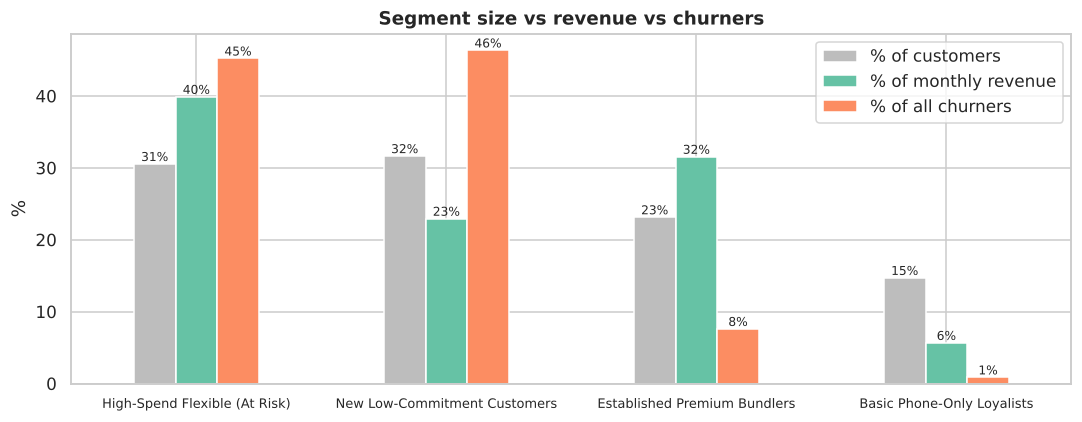

,% of customers,% of monthly revenue,% of all churners,Monthly revenue lost to churn ($)
segment,,,,
High-Spend Flexible (At Risk),30.5,39.9,45.2,75846.8
New Low-Commitment Customers,31.6,22.9,46.3,49014.1
Established Premium Bundlers,23.1,31.5,7.6,13787.2
Basic Phone-Only Loyalists,14.7,5.7,0.9,482.8


In [20]:
# --- 5.3 Share of total monthly revenue and of churners by segment ---------------------
share = pd.DataFrame({
    "% of customers": df["segment"].value_counts(normalize=True) * 100,
    "% of monthly revenue": df.groupby("segment")["MonthlyCharges"].sum() / df["MonthlyCharges"].sum() * 100,
    "% of all churners": df[df.Churn_flag == 1]["segment"].value_counts(normalize=True) * 100,
    "Monthly revenue lost to churn ($)": df[df.Churn_flag == 1].groupby("segment")["MonthlyCharges"].sum(),
}).loc[seg_order]
fig, ax = plt.subplots(figsize=(10, 4))
share[["% of customers", "% of monthly revenue", "% of all churners"]].plot.bar(ax=ax, color=["#bdbdbd", "#66c2a5", "#fc8d62"])
for c_ in ax.containers:
    ax.bar_label(c_, fmt="%.0f%%", fontsize=8)
ax.set(title="Segment size vs revenue vs churners", ylabel="%", xlabel="")
ax.tick_params(axis="x", rotation=0, labelsize=8.5)
plt.tight_layout(); plt.savefig("figures/segment_revenue_churn_share.png", bbox_inches="tight"); plt.show()
share.round(1)

## 6. Hierarchical Clustering (comparison)

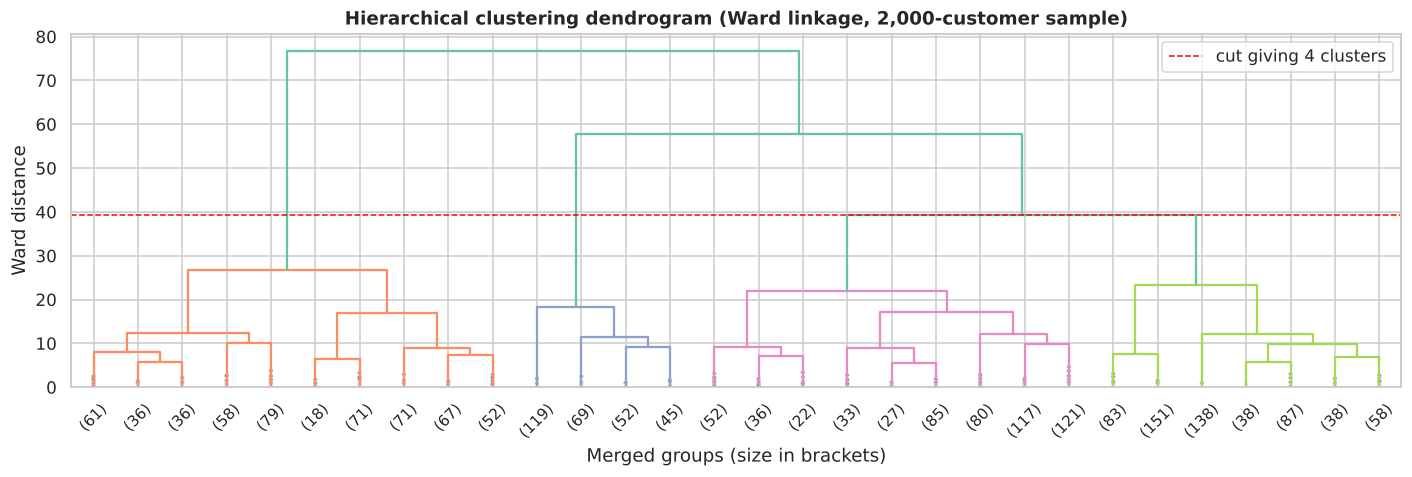

Hierarchical (Ward) silhouette: 0.323  vs  K-Means: 0.360
Adjusted Rand Index between K-Means and hierarchical clusters: 0.416 (1 = identical, 0 = random)


Hierarchical cluster,0,1,2,3
K-Means segment,,,,
Basic Phone-Only Loyalists,2,145,888,0
Established Premium Bundlers,0,820,0,809
High-Spend Flexible (At Risk),1187,964,0,0
New Low-Commitment Customers,2034,75,119,0


In [21]:
# Ward-linkage agglomerative clustering on a random sample (the full linkage matrix is O(n²) in memory)
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(Z), 2000, replace=False)
Zs = Z[sample_idx]
link = linkage(Zs, method="ward")

fig, ax = plt.subplots(figsize=(13, 4.5))
dendrogram(link, truncate_mode="lastp", p=30, ax=ax, color_threshold=link[-(K - 1), 2], show_contracted=True)
ax.axhline(link[-(K - 1), 2], color="red", ls="--", lw=1, label=f"cut giving {K} clusters")
ax.set(title="Hierarchical clustering dendrogram (Ward linkage, 2,000-customer sample)",
       xlabel="Merged groups (size in brackets)", ylabel="Ward distance")
ax.legend()
plt.tight_layout(); plt.savefig("figures/hierarchical_dendrogram.png", bbox_inches="tight"); plt.show()

# Compare with K-Means on the full data using Agglomerative clustering
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
ari = adjusted_rand_score(kmeans.labels_, agg.labels_)
print(f"Hierarchical (Ward) silhouette: {silhouette_score(Z, agg.labels_):.3f}  vs  K-Means: {silhouette_score(Z, kmeans.labels_):.3f}")
print(f"Adjusted Rand Index between K-Means and hierarchical clusters: {ari:.3f} (1 = identical, 0 = random)")
pd.crosstab(df["segment"], agg.labels_, rownames=["K-Means segment"], colnames=["Hierarchical cluster"])

**Comparison.** Ward hierarchical clustering gives a slightly lower silhouette (0.32 vs 0.36) and **agrees only partially** with K-Means
(Adjusted Rand Index ≈ 0.42). The cross-tabulation shows where they agree and differ:
- **They agree** on the two clearest groups: *Basic Phone-Only Loyalists* and *New Low-Commitment Customers* map mostly onto single hierarchical clusters.
- **They differ** on the high-spend customers. Hierarchical clustering splits *High-Spend Flexible* and *Established Premium Bundlers*
  along a different line and mixes parts of the two.

So the "new" and "phone-only" segments are robust, while the boundary between the two high-spend groups depends on the method.
K-Means is kept as the final model because it has the higher silhouette, scales to the full dataset, and its split by **contract
commitment** gives a sharper difference in churn (39% vs 9%) than the hierarchical split does, which is more useful for action.

### The identified segments
The exact sizes and percentages are in the profile table above.
- **New Low-Commitment Customers:** very short tenure, month-to-month contracts, few add-ons, low-to-medium bills, frequent electronic-check
  payment. **Very high churn.** These customers leave before they become attached to the service.
- **High-Spend Flexible (At Risk):** mid tenure, **high monthly bills** (mostly fiber optic) but still on month-to-month contracts.
  **Very high churn, and the most revenue lost.** They pay premium prices without committing, which makes them the most valuable group to retain.
- **Established Premium Bundlers:** long tenure, one- or two-year contracts, many add-ons, high bills. **Low churn.** The company's most valuable loyal base.
- **Basic Phone-Only Loyalists:** mostly no internet service, very low bills, long contracts. **Almost no churn.** Stable but low revenue; an upsell opportunity.

---
# Part C – Association Rule Mining

**Goal:** find combinations of customer attributes and services that frequently occur together, especially combinations
linked to **churn**, to **staying**, and to **buying other services** (cross-selling).

**Approach:** each customer is treated as a "transaction" (a shopping basket) whose "items" are their attribute values, for example
`Contract=Month-to-month` or `TechSupport=No`. Numeric columns are put into bins so they can become items.

**Key measures:**
- **Support:** share of all customers who have the whole itemset (how common the pattern is).
- **Confidence:** P(consequent | antecedent), how often the rule holds.
- **Lift:** confidence ÷ support of the consequent. A lift above 1 means the items occur together more often than chance would predict.

## 7. Building Transactions and Mining Frequent Itemsets

Transactions: 7,043 customers x 40 possible items


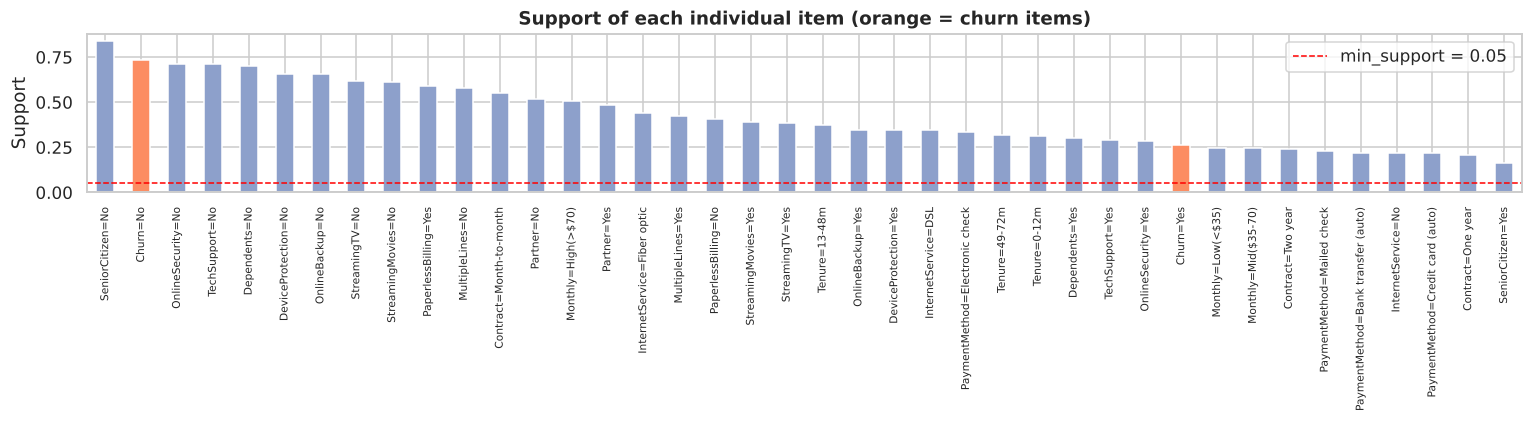

In [22]:
# --- Convert each customer into a set of boolean "items" ---------------------------
T = pd.DataFrame(index=df.index)
yes_no_cols = ["SeniorCitizen", "Partner", "Dependents", "MultipleLines", "OnlineSecurity", "OnlineBackup",
               "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling"]
for c in yes_no_cols:
    T[f"{c}=Yes"] = df[c] == "Yes"
    T[f"{c}=No"] = df[c] == "No"
for c in ["InternetService", "Contract", "PaymentMethod", "Churn"]:
    for v in sorted(df[c].unique()):
        T[f"{c}={v}"] = df[c] == v

# Discretise numeric attributes into interpretable bins
T["Tenure=0-12m"] = df["tenure"] <= 12
T["Tenure=13-48m"] = df["tenure"].between(13, 48)
T["Tenure=49-72m"] = df["tenure"] > 48
T["Monthly=Low(<$35)"] = df["MonthlyCharges"] < 35
T["Monthly=Mid($35-70)"] = df["MonthlyCharges"].between(35, 70)
T["Monthly=High(>$70)"] = df["MonthlyCharges"] > 70

# PhoneService (90% Yes) is left out: an item almost everyone has produces many trivial rules with no information.
print(f"Transactions: {T.shape[0]:,} customers x {T.shape[1]} possible items")
item_support = T.mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 4))
item_support.plot.bar(ax=ax, color=["#fc8d62" if i.startswith("Churn") else "#8da0cb" for i in item_support.index])
ax.axhline(0.05, color="red", ls="--", lw=1, label="min_support = 0.05")
ax.set(title="Support of each individual item (orange = churn items)", ylabel="Support")
ax.tick_params(axis="x", labelsize=7); ax.legend()
plt.tight_layout(); plt.savefig("figures/item_support.png", bbox_inches="tight"); plt.show()

In [23]:
# --- Apriori vs FP-Growth -------------------------------------------------------------
# min_support = 0.05: a pattern must cover at least ~350 customers to be considered,
# common enough to matter for business decisions. max_len = 4 keeps rules readable.
MIN_SUPPORT, MAX_LEN = 0.05, 4

t0 = time.time(); freq_ap = apriori(T, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN); t_ap = time.time() - t0
t0 = time.time(); freq_fp = fpgrowth(T, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN); t_fp = time.time() - t0

same = set(map(frozenset, freq_ap["itemsets"])) == set(map(frozenset, freq_fp["itemsets"]))
print(f"Apriori  : {len(freq_ap):,} frequent itemsets in {t_ap:.2f} s")
print(f"FP-Growth: {len(freq_fp):,} frequent itemsets in {t_fp:.2f} s")
print(f"Both algorithms found identical itemsets: {same}")
freq = freq_ap
freq["length"] = freq["itemsets"].apply(len)
freq.groupby("length").size().to_frame("number of frequent itemsets").T

Apriori  : 20,819 frequent itemsets in 1.72 s
FP-Growth: 20,819 frequent itemsets in 3.83 s
Both algorithms found identical itemsets: True


length,1,2,3,4
number of frequent itemsets,40,679,4989,15111


Apriori and FP-Growth return **exactly the same itemsets**, as they should, since both are exact algorithms. They differ only in speed:
Apriori generates and tests candidate itemsets level by level, while FP-Growth compresses the data into a prefix tree and avoids
candidate generation. The Apriori results are used below.

## 8. Generating and Filtering Rules

In [24]:
rules = association_rules(freq, metric="confidence", min_threshold=0.5)
rules["antecedent_str"] = rules["antecedents"].apply(lambda s: " & ".join(sorted(s)))
rules["consequent_str"] = rules["consequents"].apply(lambda s: " & ".join(sorted(s)))
rules["n_ante"] = rules["antecedents"].apply(len)
print(f"Rules with confidence >= 0.5: {len(rules):,}")

def prune_redundant(r, min_gain=0.02):
    """Remove a rule if a simpler rule (antecedent is a strict subset, same consequent) already reaches
    nearly the same confidence. Keeps only rules whose extra conditions add real predictive value."""
    r = r.sort_values("n_ante")
    keep = []
    for i, row in r.iterrows():
        simpler = r[(r["consequents"] == row["consequents"]) & (r["n_ante"] < row["n_ante"]) &
                    (r["antecedents"].apply(lambda a: a < row["antecedents"]))]
        if len(simpler) == 0 or row["confidence"] - simpler["confidence"].max() >= min_gain:
            keep.append(i)
    return r.loc[keep]

show_cols = ["antecedent_str", "consequent_str", "support", "confidence", "lift"]

Rules with confidence >= 0.5: 73,243


### 8.1 Rules that predict churn

In [25]:
churn_rules = rules[(rules["consequent_str"] == "Churn=Yes") & (rules["lift"] > 1.5)]
print(f"Churn rules with lift > 1.5 before pruning: {len(churn_rules)}")
churn_rules = prune_redundant(churn_rules).sort_values(["lift", "support"], ascending=False)
print(f"After removing redundant rules: {len(churn_rules)}")
churn_rules[show_cols].head(15).round(3).reset_index(drop=True)

Churn rules with lift > 1.5 before pruning: 263


After removing redundant rules: 179


,antecedent_str,consequent_str,support,confidence,lift
0,InternetService=Fiber optic & PaperlessBilling=Yes & Tenure=0-12m,Churn=Yes,0.074,0.723,2.724
1,Monthly=High(>$70) & PaperlessBilling=Yes & Tenure=0-12m,Churn=Yes,0.069,0.713,2.686
2,Monthly=High(>$70) & OnlineSecurity=No & Tenure=0-12m,Churn=Yes,0.078,0.708,2.669
3,Monthly=High(>$70) & TechSupport=No & Tenure=0-12m,Churn=Yes,0.076,0.701,2.642
4,InternetService=Fiber optic & Tenure=0-12m,Churn=Yes,0.092,0.699,2.633
5,Monthly=High(>$70) & Tenure=0-12m,Churn=Yes,0.084,0.679,2.558
6,PaperlessBilling=Yes & PaymentMethod=Electronic check & Tenure=0-12m,Churn=Yes,0.068,0.671,2.528
7,OnlineSecurity=No & PaymentMethod=Electronic check & Tenure=0-12m,Churn=Yes,0.080,0.643,2.422
8,PaymentMethod=Electronic check & Tenure=0-12m,Churn=Yes,0.086,0.620,2.335
9,Contract=Month-to-month & InternetService=Fiber optic & PaymentMethod=Electronic check,Churn=Yes,0.112,0.604,2.275


### 8.2 Rules that predict staying (retention patterns)

In [26]:
stay_rules = rules[(rules["consequent_str"] == "Churn=No") & (rules["confidence"] >= 0.95)]
stay_rules = prune_redundant(stay_rules, min_gain=0.01).sort_values(["support", "confidence"], ascending=False)
print(f"Retention rules (confidence >= 95%, non-redundant): {len(stay_rules)}")
stay_rules[show_cols].head(10).round(3).reset_index(drop=True)

Retention rules (confidence >= 95%, non-redundant): 69


,antecedent_str,consequent_str,support,confidence,lift
0,Contract=Two year,Churn=No,0.234,0.972,1.323
1,StreamingTV=No & Tenure=49-72m,Churn=No,0.137,0.955,1.301
2,StreamingMovies=No & Tenure=49-72m,Churn=No,0.134,0.953,1.298
3,Contract=Two year & StreamingTV=No,Churn=No,0.131,0.987,1.344
4,Contract=Two year & StreamingMovies=No,Churn=No,0.130,0.985,1.341
5,Contract=Two year & PaperlessBilling=No,Churn=No,0.127,0.984,1.339
6,Contract=Two year & DeviceProtection=No,Churn=No,0.122,0.984,1.339
7,Contract=Two year & MultipleLines=No,Churn=No,0.115,0.984,1.340
8,Contract=One year & StreamingMovies=No,Churn=No,0.110,0.953,1.297
9,InternetService=DSL & Tenure=49-72m,Churn=No,0.107,0.957,1.302


### 8.3 Cross-sell rules between services

In [27]:
service_items = [f"{c}=Yes" for c in ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                                      "TechSupport", "StreamingTV", "StreamingMovies"]] + ["InternetService=Fiber optic"]
is_service_set = lambda s: all(i in service_items for i in s)
xsell = rules[rules["antecedents"].apply(is_service_set) & rules["consequents"].apply(is_service_set)
              & (rules["consequents"].apply(len) == 1) & (rules["lift"] > 1.3)]
xsell = prune_redundant(xsell).sort_values("lift", ascending=False)
print(f"Cross-sell rules (service -> service, lift > 1.3): {len(xsell)}")
xsell[show_cols].head(12).round(3).reset_index(drop=True)

Cross-sell rules (service -> service, lift > 1.3): 236


,antecedent_str,consequent_str,support,confidence,lift
0,DeviceProtection=Yes & OnlineSecurity=Yes & StreamingMovies=Yes,TechSupport=Yes,0.073,0.699,2.407
1,DeviceProtection=Yes & OnlineSecurity=Yes & StreamingTV=Yes,TechSupport=Yes,0.071,0.695,2.395
2,OnlineBackup=Yes & OnlineSecurity=Yes & StreamingTV=Yes,TechSupport=Yes,0.062,0.679,2.338
3,DeviceProtection=Yes & OnlineBackup=Yes & OnlineSecurity=Yes,TechSupport=Yes,0.067,0.678,2.337
4,OnlineBackup=Yes & OnlineSecurity=Yes & StreamingMovies=Yes,TechSupport=Yes,0.062,0.676,2.331
5,DeviceProtection=Yes & MultipleLines=Yes & OnlineSecurity=Yes,TechSupport=Yes,0.060,0.669,2.304
6,OnlineSecurity=Yes & StreamingMovies=Yes & StreamingTV=Yes,TechSupport=Yes,0.072,0.657,2.263
7,DeviceProtection=Yes & OnlineBackup=Yes & TechSupport=Yes,OnlineSecurity=Yes,0.067,0.647,2.258
8,OnlineSecurity=Yes & StreamingMovies=Yes & TechSupport=Yes,DeviceProtection=Yes,0.073,0.769,2.237
9,OnlineSecurity=Yes & StreamingTV=Yes & TechSupport=Yes,DeviceProtection=Yes,0.071,0.763,2.220


### 8.4 Visualising the rules

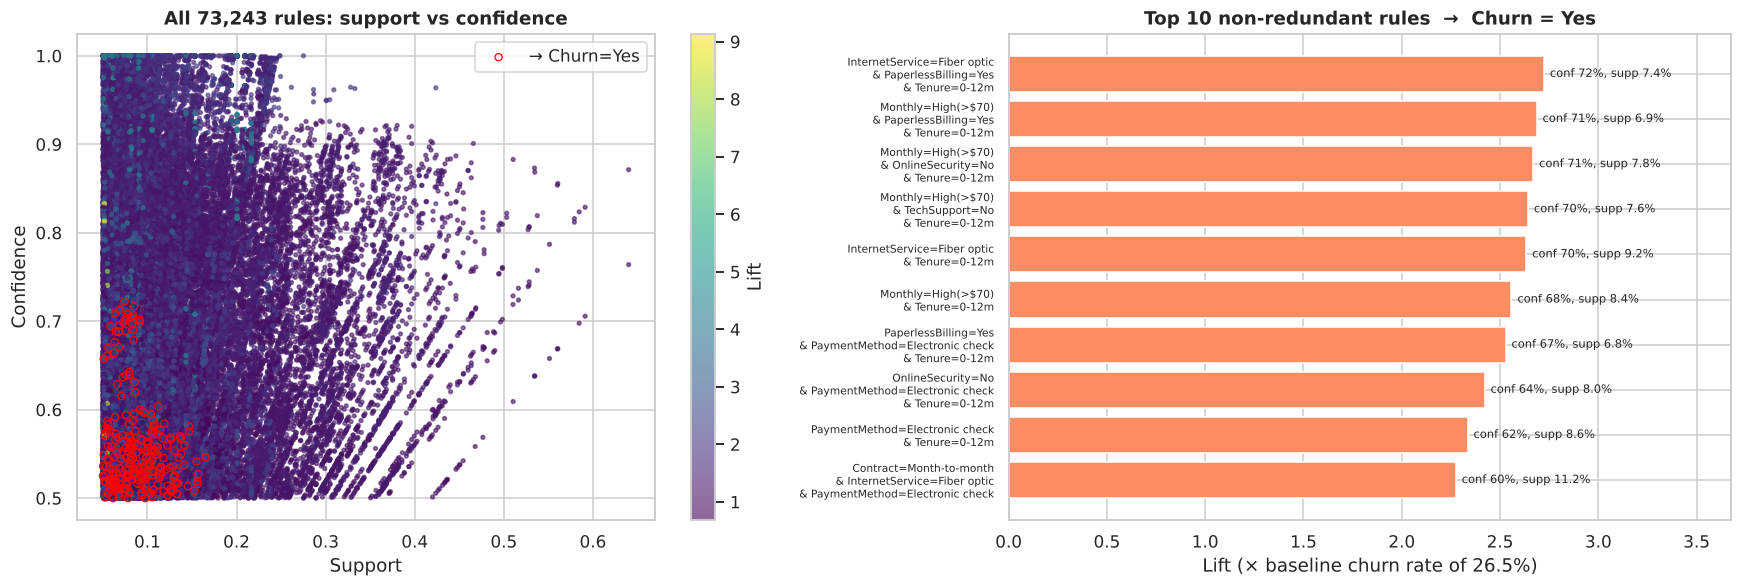

In [28]:
# --- Support vs confidence for all rules, coloured by lift ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sc = axes[0].scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=6, alpha=.6)
plt.colorbar(sc, ax=axes[0], label="Lift")
cr = rules[rules["consequent_str"] == "Churn=Yes"]
axes[0].scatter(cr["support"], cr["confidence"], facecolors="none", edgecolors="red", s=22, lw=.8, label="→ Churn=Yes")
axes[0].set(title=f"All {len(rules):,} rules: support vs confidence", xlabel="Support", ylabel="Confidence")
axes[0].legend()

# --- Top non-redundant churn rules by lift ------------------------------------------
top_cr = churn_rules.head(10).iloc[::-1]
bars = axes[1].barh(top_cr["antecedent_str"].str.replace(" & ", "\n& ", regex=False), top_cr["lift"], color="#fc8d62")
for b, (conf, sup) in zip(bars, zip(top_cr["confidence"], top_cr["support"])):
    axes[1].text(b.get_width() + 0.03, b.get_y() + b.get_height() / 2, f"conf {conf:.0%}, supp {sup:.1%}",
                 va="center", fontsize=7.5)
axes[1].set(title="Top 10 non-redundant rules  →  Churn = Yes", xlabel="Lift (× baseline churn rate of 26.5%)",
            xlim=(0, top_cr["lift"].max() * 1.35))
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig("figures/association_rules_overview.png", bbox_inches="tight"); plt.show()

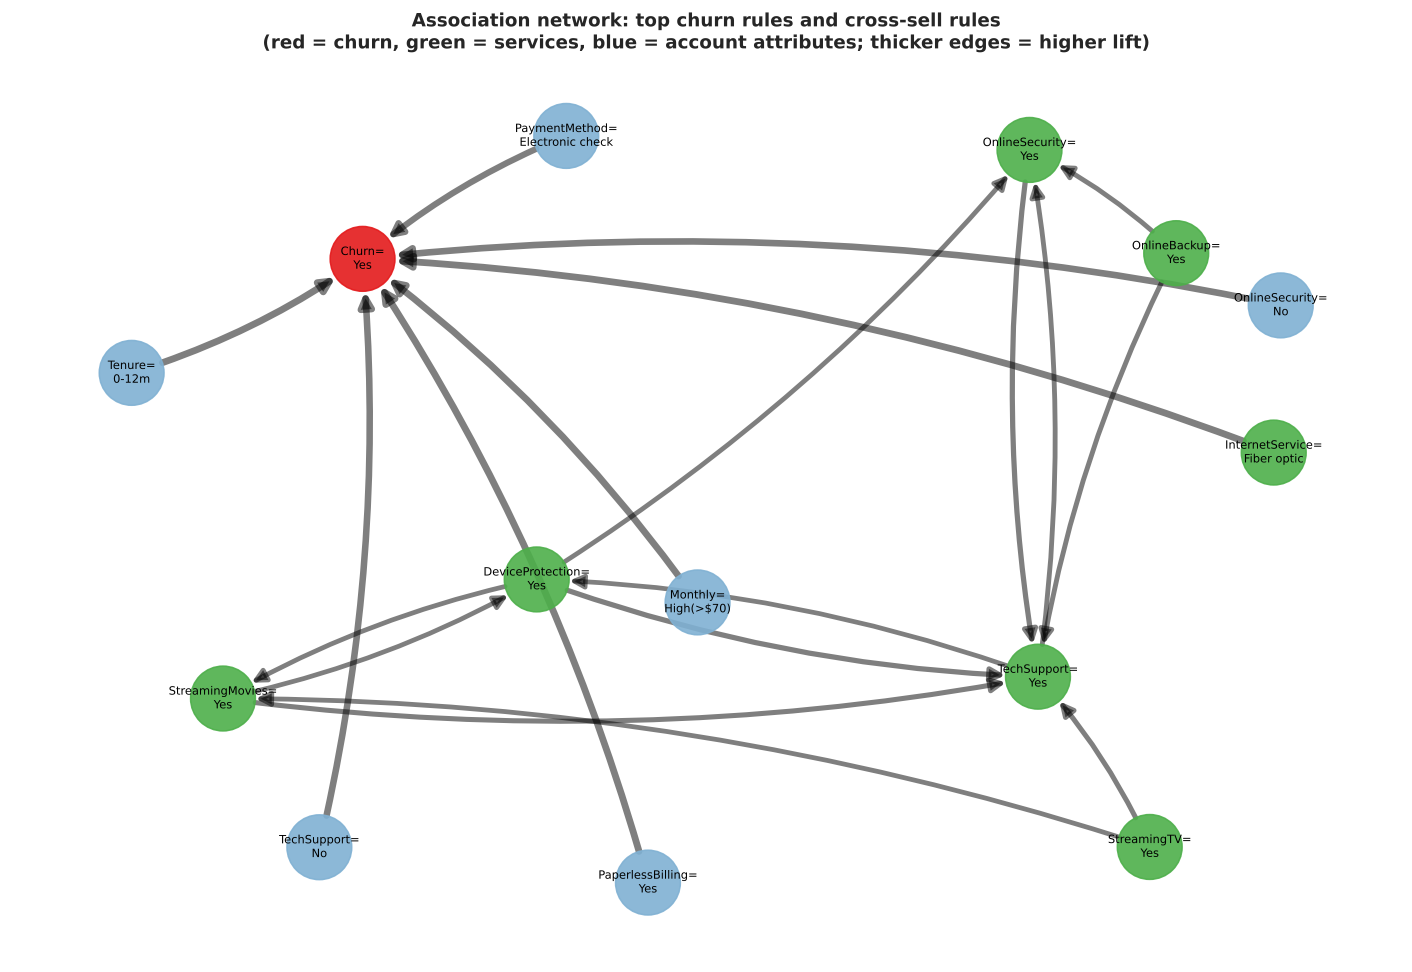

In [29]:
# --- Network graph of the strongest rules involving churn and services ---------------
G = nx.DiGraph()
net_rules = pd.concat([churn_rules.head(8), xsell[xsell["n_ante"] <= 2].head(8)])
for _, r in net_rules.iterrows():
    for a in r["antecedents"]:
        for c in r["consequents"]:
            if G.has_edge(a, c):
                G[a][c]["lift"] = max(G[a][c]["lift"], r["lift"])
            else:
                G.add_edge(a, c, lift=r["lift"])

fig, ax = plt.subplots(figsize=(13, 9))
pos = nx.spring_layout(G, k=1.6, seed=7)
node_col = ["#e41a1c" if n.startswith("Churn") else "#4daf4a" if n in service_items else "#80b1d3" for n in G.nodes]
widths = [1 + 2 * (G[u][v]["lift"] - 1) for u, v in G.edges]
nx.draw_networkx_nodes(G, pos, node_color=node_col, node_size=1800, alpha=.9, ax=ax)
nx.draw_networkx_edges(G, pos, width=widths, alpha=.5, arrowsize=18, ax=ax, connectionstyle="arc3,rad=0.08",
                       node_size=1800)
nx.draw_networkx_labels(G, pos, labels={n: n.replace("=", "=\n") for n in G.nodes}, font_size=7.5, ax=ax)
ax.set_title("Association network: top churn rules and cross-sell rules\n"
             "(red = churn, green = services, blue = account attributes; thicker edges = higher lift)")
ax.axis("off")
plt.tight_layout(); plt.savefig("figures/association_network.png", bbox_inches="tight"); plt.show()

## 9. Applying the Patterns in the Real World

| Pattern discovered | Real-world application |
|---|---|
| **{Fiber optic, tenure ≤ 12 months, …} → Churn** (about 70% confidence, lift ≈ 2.6–2.7) | **Early-life retention programme:** automatically flag new fiber customers for an onboarding call, a first-year loyalty discount, or a service-quality check during months 1–12. |
| **{…, OnlineSecurity = No / TechSupport = No} → Churn** | **Bundle protection services into fiber plans** (free 3-month trial of TechSupport/OnlineSecurity), since customers with these add-ons churn about half as often. |
| **{Electronic check, Month-to-month, …} → Churn** | **Nudge customers to automatic payments** (small bill credit). Combined with the classification results, this is a cheap, targeted intervention. |
| **{Two-year contract} → Stay** (97% confidence; up to 99% with other conditions) | **Contract-upgrade campaigns:** offer at-risk month-to-month customers a discounted 1–2 year contract; contracts almost guarantee retention. |
| **{StreamingTV} → {StreamingMovies}** (72% confidence, lift 1.85, 28% of customers) and **{OnlineSecurity, DeviceProtection} → TechSupport** (64%, lift 2.2) | **Cross-sell recommendations:** a "customers who have X also have Y" engine for the call centre and web portal, and natural **service bundles** (an entertainment pack, a protection pack). |
| Rules as simple IF–THEN statements | Business teams can apply them **without a machine-learning system**, for example as filters in the CRM to build campaign target lists. |

---
# Part D – Summary of Insights

In [30]:
best_f1 = results["F1"].idxmax(); best_auc = results["ROC-AUC"].idxmax()
print("CLASSIFICATION")
print(results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].round(3).to_string())
print(f"\nBest F1: {best_f1} ({results.loc[best_f1, 'F1']:.3f}); best ROC-AUC: {best_auc} ({results.loc[best_auc, 'ROC-AUC']:.3f})")
print(f"Tuned tree parameters: {grid.best_params_}")
print("\nCLUSTERING (K-Means, k = 4)")
print(profile[["customers", "tenure", "monthly_charges", "num_addons", "pct_month_to_month", "churn_rate"]].round(1).to_string())
print(f"K-Means vs hierarchical ARI = {ari:.3f}")
print("\nASSOCIATION RULES")
print(f"{len(freq):,} frequent itemsets, {len(rules):,} rules; {len(churn_rules)} non-redundant churn rules, "
      f"{len(stay_rules)} retention rules, {len(xsell)} cross-sell rules")
print("Strongest churn rule:", churn_rules.iloc[0]["antecedent_str"],
      f"-> Churn=Yes (conf {churn_rules.iloc[0]['confidence']:.1%}, lift {churn_rules.iloc[0]['lift']:.2f})")

CLASSIFICATION
                         Accuracy  Precision  Recall     F1  ROC-AUC
Decision Tree (default)     0.730      0.492   0.505  0.499    0.658
Decision Tree (tuned)       0.746      0.514   0.783  0.621    0.816
k-NN                        0.776      0.580   0.570  0.575    0.819
Naive Bayes                 0.732      0.497   0.778  0.606    0.821
SVM (RBF)                   0.742      0.509   0.757  0.609    0.818
Logistic Regression         0.739      0.505   0.781  0.613    0.841

Best F1: Decision Tree (tuned) (0.621); best ROC-AUC: Logistic Regression (0.841)
Tuned tree parameters: {'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}

CLUSTERING (K-Means, k = 4)
                               customers  tenure  monthly_charges  num_addons  pct_month_to_month  churn_rate
cluster_id                                                                                                   
High-Spend Flexible (At Risk)       2151

**All three techniques point to the same churn story from different angles:**

1. **Classification** shows that churn can be predicted with ROC-AUC ≈ 0.82–0.84. Hyperparameter tuning turned the Decision Tree from the
   weakest model into a competitive, interpretable one, with contract type, tenure and fiber internet as its top splits.
2. **Clustering** finds four natural customer segments. Two of them (new low-commitment customers and high-spend customers without contracts)
   account for the vast majority of churners. The high-spend flexible segment represents the largest share of lost revenue.
3. **Association rules** turn these findings into simple IF–THEN patterns: new fiber customers without protection services
   churn at about 70% (about 2.6–2.7× the baseline), two-year contracts retain 97% of customers, and service add-ons cluster into natural bundles.

**Bridge to Deliverable 4:** these results will be brought together into recommendations: early-life retention for new fiber customers,
contract-upgrade and auto-pay incentives for the at-risk segments, and protection-service bundles. Ethical aspects (for example the use of
the senior-citizen attribute in targeting) will also be considered.